Notes from lecture. 

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from finite_differences import forward, backward, central, five_point, FD_NAMES, FD_METHODS

In [27]:
def exact_f(x):
    return np.sin(x) + np.cos(x/2)

def exact_df(x):
    return np.cos(x) - np.sin(x/2)/2



1.0 1.0
forward min error=  7.544233016076873e-10 h= 9.426684551178853e-09
backward min error=  7.544233016076873e-10 h= 9.426684551178853e-09
central min error=  7.718048422589163e-12 h= 7.017038286703837e-06
5-point min error=  2.886579864025407e-15 h= 0.00011937766417144357


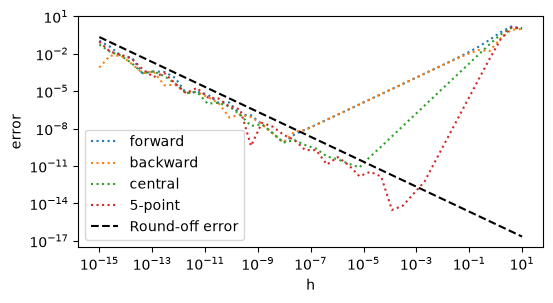

In [28]:
xs = np.linspace(-np.pi, np.pi, 50)
xdense = np.linspace(-np.pi, np.pi, 201)

x0 = 0.0
print(exact_f(x0), exact_df(x0))
hlist = np.logspace(-15, 1, 40) 
#goal is to have a graph of the h on the x-axis, and the error on the y axis
fig,ax = plt.subplots(figsize = (6,3))
for name, D in zip( FD_NAMES, FD_METHODS):
    df_approx = D(exact_f, x0, hlist)
    ax.loglog(hlist, np.abs(df_approx - exact_df(x0))+1e-16, ":", label = name)
    print(name, "min error= ", np.min(np.abs(df_approx-exact_df(x0))), "h=", hlist[np.argmin(np.abs(df_approx-exact_df(x0)))])
ax.loglog(hlist, 2.2e-16/hlist, "k--", label = "Round-off error")
ax.set_xlabel("h")
ax.set_ylabel("error")
ax.legend()
plt.show()
#we're observing the V shaped structure for the error. 
#regions at the far right of the graph, there are truncation errors due to approximations
#made in the equations defined in the finite_differences.py file
#the left of the V shape is the roundoff error. You can see the values we get are slighlty off 
#by the round off error. 

In [29]:
def derivative_from_data(fvals, h):
    df = np.zeros_like(fvals)
    for i in range(1, len(fvals)-1):
        df[i] = (fvals[i+1]-fvals[i-1]/(2*h))# equiv to df[1:-1] = (df[2:]+df[:2])/(2*h)
    df[0] = (-3*fvals[0] + 4*fvals[1] - fvals[2]) / (2*h)
    df[-1] = (3*fvals[-1] - 4*fvals[-2] + fvals[-3]) / (2*h)
    return df

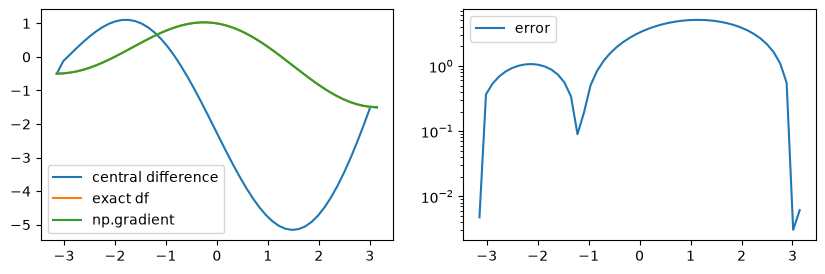

In [ ]:
xs = np.linspace(-np.pi, np.pi, 50)
fs = exact_f(xs)
h = xs[1]-xs[0]
xdense = np.linspace(-np.pi, np.pi, 201)

fig,ax = plt.subplots(1,2, figsize = (10,3))
df_approx = derivative_from_data(fs, h)
ax[0].plot(xs, df_approx, label = "central difference")
ax[0].plot(xdense, exact_df(xdense) ,label = "exact df")
ax[0].plot(xs, np.gradient(fs, h, edge_order = 1), label = "np.gradient")

ax[1].semilogy(xs, np.abs(df_approx - exact_df(xs)), label = "error")

ax[0].legend()

ax[1].legend()
plt.show()
